# PDO Cell Painting pipeline figure

A publication-style schematic of the workflow, drawn entirely from matplotlib polygons:

1. **Patient-derived organoids** — patients → tumour samples → organoid growth → 96-well plate + drugs
2. **Cell Painting + high-content volumetric imaging** — AGP, DNA, ER and Mito z-stacks
3. **2.5D/3D segmentation** — nuclei, cells, cytoplasm and whole-organoid masks

The figure is sized for a 180 mm double-column journal width with 6–9 pt text, and is exported as
vector PDF/SVG (editable text) plus a 600 dpi PNG.

**Requires:** `numpy`, `matplotlib`, `scipy`

> The micrographs are synthetic. To use real data, replace the arrays returned by
> `channel_images()` with your own 2D max-projections scaled to 0–1 (see the note in that section).

In [1]:
import pathlib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon, RegularPolygon
from notebook_init_utils.notebook_init_utils import init_notebook
from scipy.ndimage import gaussian_filter
from scipy.spatial import Voronoi

root_dir, in_notebook = init_notebook()

In [2]:
output_figure_file_path = pathlib.Path(
    f"{root_dir}/figures/workflow_figures/figures/pdo_pipeline_figure.png"
)
output_figure_file_path.parent.mkdir(parents=True, exist_ok=True)

## Settings
Fonts fall back from Arial → Helvetica → Liberation Sans → DejaVu Sans, depending on what is installed.
`rng` fixes the random organoid layout — change the seed for a different arrangement.
Drawing coordinates are in abstract units on a `W × H` canvas; the figure is scaled to `FIG_W_IN` inches wide.

In [3]:
mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "pdf.fonttype": 42,  # editable TrueType text in PDF
        "ps.fonttype": 42,
        "svg.fonttype": "none",  # keep text as text in SVG
    }
)

rng = np.random.default_rng(7)

W, H = 20.0, 8.4  # drawing units
FIG_W_IN = 180 / 25.4  # 180 mm double-column width
INK = "#222222"
GREY = "#6b6b6b"
LIGHT = "#eceef1"
LW = 0.7  # standard stroke (pt)
SEG_CMAP = plt.get_cmap("cividis")

FS_TITLE, FS_LABEL, FS_SMALL, FS_LETTER = 11, 9, 7, 13

## Polygon helpers
Every shape in the figure is a `Polygon`: bevelled boxes (`chamfer`), arrows (`arrow_poly`), and multi-segment connectors (`elbow_arrow`).

In [4]:
def chamfer(x, y, w, h, c=0.1):
    """Rectangle with small cut corners."""
    return np.array(
        [
            (x + c, y),
            (x + w - c, y),
            (x + w, y + c),
            (x + w, y + h - c),
            (x + w - c, y + h),
            (x + c, y + h),
            (x, y + h - c),
            (x, y + c),
        ]
    )


def poly(ax, verts, fc="none", ec=INK, lw=LW, z=3, **kw):
    p = Polygon(
        verts, closed=True, fc=fc, ec=ec, lw=lw, zorder=z, joinstyle="miter", **kw
    )
    ax.add_patch(p)
    return p


def arrow_poly(p0, p1, w=0.1, hw=0.3, hl=0.26):
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    a = p1 - u * hl
    return np.array(
        [
            p0 + n * w / 2,
            a + n * w / 2,
            a + n * hw / 2,
            p1,
            a - n * hw / 2,
            a - n * w / 2,
            p0 - n * w / 2,
        ]
    )


def arrow(ax, p0, p1, color=INK, z=8, **kw):
    poly(ax, arrow_poly(p0, p1, **kw), fc=color, ec="none", z=z)


def elbow_arrow(ax, pts, color=INK, w=0.1, z=8):
    pts = [np.asarray(p, float) for p in pts]
    for k, (a, b) in enumerate(zip(pts[:-2], pts[1:-1])):
        u = (b - a) / np.linalg.norm(b - a)
        n = np.array([-u[1], u[0]])
        a2 = a - (u * w / 2 if k else 0)
        b2 = b + u * w / 2
        poly(
            ax,
            [a2 + n * w / 2, b2 + n * w / 2, b2 - n * w / 2, a2 - n * w / 2],
            fc=color,
            ec="none",
            z=z,
        )
    arrow(ax, pts[-2], pts[-1], color, z=z, w=w)


def text(
    ax,
    x,
    y,
    s,
    size=FS_LABEL,
    color=INK,
    weight="normal",
    ha="center",
    va="center",
    **kw,
):
    ax.text(
        x,
        y,
        s,
        fontsize=size,
        color=color,
        weight=weight,
        ha=ha,
        va=va,
        zorder=20,
        linespacing=1.1,
        **kw,
    )

## Organoid geometry
One organoid is generated here and reused in every panel so the imaging and segmentation views match:
a wobbly outline (`BLOB`), cell centres (`SEEDS`), Voronoi cell polygons (`CELLS`) and irregular nuclei (`NUCLEI`).
Label colours are sampled from the colourblind-safe **cividis** colormap.

In [5]:
def r_fun(th):
    return 0.72 * (1 + 0.07 * np.sin(3 * th + 0.4) + 0.05 * np.cos(5 * th + 1.1))


def sample_seeds(n=26, min_d=0.17):
    seeds = []
    while len(seeds) < n:
        p = rng.uniform(-0.8, 0.8, 2)
        rho, th = np.hypot(*p), np.arctan2(p[1], p[0])
        if rho < r_fun(th) - 0.07 and all(np.hypot(*(p - q)) > min_d for q in seeds):
            seeds.append(p)
    return np.array(seeds)


SEEDS = sample_seeds()
THETA = np.linspace(0, 2 * np.pi, 220, endpoint=False)
BLOB = np.c_[r_fun(THETA) * np.cos(THETA), r_fun(THETA) * np.sin(THETA)]
LABEL_COLORS = [SEG_CMAP(v) for v in rng.uniform(0.12, 0.95, len(SEEDS))]


def voronoi_polys(seeds):
    far = np.array([[-10, -10], [10, -10], [10, 10], [-10, 10]])
    vor = Voronoi(np.vstack([seeds, far]))
    out = []
    for i in range(len(seeds)):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        out.append(v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))])
    return out


CELLS = voronoi_polys(SEEDS)


def nucleus_poly(c, k=11):
    a, b = rng.uniform(0.06, 0.085), rng.uniform(0.045, 0.065)
    rot = rng.uniform(0, np.pi)
    t = np.linspace(0, 2 * np.pi, k, endpoint=False)
    rr = 1 + rng.normal(0, 0.08, k)
    x, y = a * rr * np.cos(t), b * rr * np.sin(t)
    return (
        np.c_[x * np.cos(rot) - y * np.sin(rot), x * np.sin(rot) + y * np.cos(rot)] + c
    )


NUCLEI = [nucleus_poly(s) for s in SEEDS]


def to_frame(uv, x, y, s):
    uv = np.asarray(uv)
    return np.c_[x + (uv[:, 0] + 1) / 2 * s, y + (uv[:, 1] + 1) / 2 * s]

## Cell Painting channels
Synthetic grayscale images built from the same geometry: membranes (AGP), nuclei (DNA), perinuclear rings (ER) and punctate signal (Mito).

**To use real images:** replace this function with one that returns a dict
`{"AGP": array, "DNA": array, "ER": array, "Mito": array}` of 2D arrays scaled to 0–1.

In [6]:
def channel_images(n=300):
    g = np.linspace(-1, 1, n)
    uu, vv = np.meshgrid(g, g)
    rho, th = np.hypot(uu, vv), np.arctan2(vv, uu)
    r = r_fun(th)
    inside = 1 / (1 + np.exp(-(r - rho) / 0.015))
    rim = np.exp(-(((rho - r) / 0.03) ** 2))
    d = np.sort(
        np.hypot(
            uu[None] - SEEDS[:, 0, None, None], vv[None] - SEEDS[:, 1, None, None]
        ),
        axis=0,
    )
    d1, d2 = d[0], d[1]
    membrane = np.exp(-(((d2 - d1) / 0.022) ** 2))
    nuc = np.exp(-((d1 / 0.06) ** 4))
    speck = gaussian_filter(rng.random((n, n)), 1.3)
    speck = ((speck - speck.min()) / np.ptp(speck)) ** 5 * 3
    bg = gaussian_filter(rng.random((n, n)), 1) * 0.05
    imgs = {
        "AGP": inside * (0.1 + 0.8 * membrane) + 0.45 * rim,
        "DNA": inside * nuc * (0.7 + 0.3 * gaussian_filter(rng.random((n, n)), 2)),
        "ER": inside * (0.2 + 0.55 * np.exp(-(((d1 - 0.1) / 0.035) ** 2))) + 0.5 * rim,
        "Mito": inside * (1 - nuc) * (0.1 + 0.8 * speck) + 0.2 * rim,
    }
    return {k: np.clip(v + bg, 0, 1) for k, v in imgs.items()}

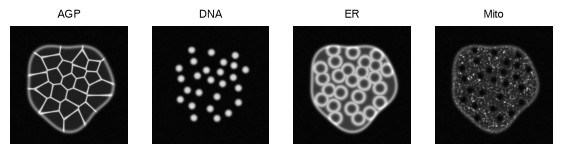

In [7]:
# Quick preview of the four channels
imgs_preview = channel_images()
fig_prev, axes = plt.subplots(1, 4, figsize=(7, 1.9))
for a, (name, img) in zip(axes, imgs_preview.items()):
    a.imshow(img, cmap="gray", origin="lower", vmin=0, vmax=1)
    a.set_title(name, fontsize=8)
    a.axis("off")
plt.show()

## z-stacks and segmentation renderers
`stack` draws a pile of offset slices with content clipped into the front slice.
The `seg_*` functions draw the label maps; `channel_drawer` wraps a channel image for the imaging panel.

In [8]:
def stack(ax, x, y, s, draw_front, n=6, off=0.055, z=10):
    for i in range(n - 1, 0, -1):
        poly(
            ax,
            [
                (x - i * off, y + i * off),
                (x - i * off + s, y + i * off),
                (x - i * off + s, y + i * off + s),
                (x - i * off, y + i * off + s),
            ],
            fc="white",
            ec=GREY,
            lw=0.5,
            z=z,
        )
    clip = poly(
        ax,
        [(x, y), (x + s, y), (x + s, y + s), (x, y + s)],
        fc="black",
        ec=INK,
        lw=0.6,
        z=z + 0.5,
    )
    draw_front(ax, x, y, s, clip, z + 1)


def seg_nuclei(ax, x, y, s, clip, z):
    for pv, c in zip(NUCLEI, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="none", z=z)
        p.set_clip_path(clip)


def seg_cells(ax, x, y, s, clip, z, cyto=False):
    blob = poly(ax, to_frame(BLOB, x, y, s), fc="none", ec="none", z=z)
    for pv, c in zip(CELLS, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="black", lw=0.3, z=z)
        p.set_clip_path(blob)
    if cyto:
        for pv in NUCLEI:
            poly(ax, to_frame(pv, x, y, s), fc="black", ec="none", z=z + 0.3)


def seg_organoid(ax, x, y, s, clip, z):
    poly(ax, to_frame(BLOB, x, y, s), fc=SEG_CMAP(0.75), ec="none", z=z)


def channel_drawer(img):
    def draw(ax, x, y, s, clip, z):
        im = ax.imshow(
            img,
            extent=[x, x + s, y, y + s],
            cmap="gray",
            vmin=0,
            vmax=1,
            origin="lower",
            zorder=z,
            interpolation="bilinear",
        )
        im.set_clip_path(clip)

    return draw

## Icons
Outline-style icons for the organoid and imaging panels, plus `mini_organoid` for the growth sequence
(single cell → cluster → organoid), each built from Voronoi cells clipped to a round polygon.

In [9]:
def person(ax, cx, cy):
    t = np.linspace(0, 2 * np.pi, 40, endpoint=False)
    poly(ax, np.c_[cx + 0.24 * np.cos(t), cy + 0.68 + 0.24 * np.sin(t)], fc=LIGHT)
    poly(ax, chamfer(cx - 0.34, cy - 0.38, 0.68, 0.78, 0.18), fc=LIGHT)


def tube(ax, cx, cy):
    poly(
        ax,
        [
            (cx - 0.16, cy + 0.4),
            (cx + 0.16, cy + 0.4),
            (cx + 0.16, cy - 0.15),
            (cx, cy - 0.52),
            (cx - 0.16, cy - 0.15),
        ],
        fc="white",
    )
    poly(
        ax,
        [
            (cx - 0.16, cy - 0.02),
            (cx + 0.16, cy - 0.02),
            (cx + 0.16, cy - 0.15),
            (cx, cy - 0.52),
            (cx - 0.16, cy - 0.15),
        ],
        fc="#b9bec7",
        ec="none",
        z=3.2,
    )
    poly(ax, chamfer(cx - 0.21, cy + 0.4, 0.42, 0.14, 0.03), fc=LIGHT, z=3.3)


def plate(ax, x, y, w, h):
    poly(ax, chamfer(x, y, w, h, 0.12), fc="white")
    cmap = LinearSegmentedColormap.from_list("dose", ["#ffffff", "#5b6b82"])
    dx, dy = (w - 0.3) / 12, (h - 0.25) / 8
    for i in range(8):
        for j in range(12):
            ax.add_patch(
                RegularPolygon(
                    (x + 0.15 + dx * (j + 0.5), y + 0.12 + dy * (i + 0.5)),
                    24,
                    radius=min(dx, dy) * 0.4,
                    fc=cmap(j / 11),
                    ec=INK,
                    lw=0.3,
                    zorder=4,
                )
            )


def pill(ax, cx, cy, length=0.9, r=0.19, angle=40):
    t = np.linspace(-np.pi / 2, np.pi / 2, 16)
    half = length / 2 - r
    right = np.c_[half + r * np.cos(t), r * np.sin(t)]
    left = np.c_[-half - r * np.cos(t), r * np.sin(t)][::-1]
    a = np.deg2rad(angle)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    rot = lambda v: v @ R.T + [cx, cy]
    poly(ax, rot(np.vstack([[0, -r], right, [0, r]])), fc="#5b6b82")
    poly(ax, rot(np.vstack([[0, r], left, [0, -r]])), fc="white")


def microscope(ax, x, y):
    poly(ax, chamfer(x, y, 1.2, 0.16, 0.04), fc=LIGHT)  # base
    poly(
        ax,
        [
            (x + 0.88, y + 0.16),
            (x + 1.06, y + 0.16),
            (x + 1.06, y + 1.4),
            (x + 0.73, y + 1.76),
            (x + 0.6, y + 1.63),
            (x + 0.88, y + 1.33),
        ],
        fc=LIGHT,
    )  # arm
    poly(ax, chamfer(x + 0.15, y + 0.6, 0.92, 0.1, 0.02), fc=LIGHT)  # stage
    p0, p1 = np.array([x + 0.42, y + 0.9]), np.array([x + 0.8, y + 1.98])
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    poly(
        ax,
        [p0 + n * 0.12, p1 + n * 0.12, p1 - n * 0.12, p0 - n * 0.12],
        fc="white",
        z=3.5,
    )
    poly(
        ax,
        [
            p1 + n * 0.16,
            p1 + n * 0.16 + u * 0.13,
            p1 - n * 0.16 + u * 0.13,
            p1 - n * 0.16,
        ],
        fc=GREY,
        z=3.6,
    )  # eyepiece
    poly(
        ax,
        [
            p0 + n * 0.08,
            p0 - n * 0.08,
            p0 - n * 0.05 - u * 0.15,
            p0 + n * 0.05 - u * 0.15,
        ],
        fc=GREY,
        z=3.6,
    )  # objective


def mini_organoid(ax, cx, cy, r, n_cells, rng_local):
    """Small organoid icon: Voronoi cells clipped to a round polygon, with nuclei."""
    t = np.linspace(0, 2 * np.pi, 48, endpoint=False)
    wob = 1 + 0.05 * np.sin(3 * t + cx) if n_cells > 1 else 1
    outline = np.c_[cx + r * wob * np.cos(t), cy + r * wob * np.sin(t)]
    if n_cells == 1:
        seeds = np.array([[cx, cy]])
    else:
        seeds, min_d = [], r * 1.1 / np.sqrt(n_cells)
        for _ in range(20000):
            if len(seeds) == n_cells:
                break
            p = rng_local.uniform(-0.8 * r, 0.8 * r, 2)
            if np.hypot(*p) < 0.8 * r and all(
                np.hypot(*(p - q)) > min_d for q in seeds
            ):
                seeds.append(p)
        seeds = np.array(seeds) + [cx, cy]
    clip = poly(ax, outline, fc="none", ec="none", z=4)
    far = np.array(
        [[cx - 50, cy - 50], [cx + 50, cy - 50], [cx + 50, cy + 50], [cx - 50, cy + 50]]
    )
    vor = Voronoi(np.vstack([seeds, far]))
    for i, s in enumerate(seeds):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        v = v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))]
        p = poly(ax, v, fc="#dfe3e8", ec=GREY, lw=0.3, z=4)
        p.set_clip_path(clip)
        nr = r * 0.3 if n_cells == 1 else r * 0.42 / np.sqrt(n_cells)
        poly(
            ax,
            np.c_[s[0] + nr * np.cos(t[::4]), s[1] + nr * np.sin(t[::4])],
            fc="#5b6b82",
            ec="none",
            z=4.2,
        )
    poly(ax, outline, fc="none", ec=INK, lw=0.6, z=4.3)

## Panel frame
A light-grey header bar above a dashed body.

In [10]:
def panel(ax, x, y_body, w, h_body, h_head, title):
    poly(ax, chamfer(x, y_body, w, h_body, 0.12), ec=GREY, lw=0.6, ls=(0, (3, 2)), z=1)
    hy = y_body + h_body + 0.15
    poly(ax, chamfer(x, hy, w, h_head, 0.12), fc=LIGHT, ec=INK, lw=0.6, z=2)
    text(ax, x + w / 2, hy + h_head / 2, title, FS_TITLE, weight="bold")

## Build the figure
All positions are in drawing units. The three panels are laid out top-left, top-right and bottom,
joined by arrows in workflow order (organoids → imaging → segmentation).

In [11]:
def build_figure():
    fig = plt.figure(figsize=(FIG_W_IN, FIG_W_IN * H / W), facecolor="white")
    ax = fig.add_axes([0, 0, 1, 1])

    # a — Patient-derived organoids
    panel(ax, 0.3, 4.5, 7.45, 2.6, 0.95, "Patient-derived organoids (PDOs)")
    arrow_kw = dict(w=0.08, hw=0.24, hl=0.18)
    LY, LKW = 5.2, dict(size=FS_SMALL, va="top")
    person(ax, 0.82, 5.85)
    text(ax, 0.82, LY, "Patients", **LKW)
    arrow(ax, (1.24, 5.95), (1.54, 5.95), **arrow_kw)
    tube(ax, 1.85, 5.95)
    text(ax, 1.85, LY, "Tumour\nsamples", **LKW)
    arrow(ax, (2.15, 5.95), (2.49, 5.95), **arrow_kw)
    # organoid growth: single cell -> cluster -> organoid
    rng_g = np.random.default_rng(3)
    mini_organoid(ax, 2.72, 5.95, 0.11, 1, rng_g)
    mini_organoid(ax, 3.14, 5.95, 0.2, 4, rng_g)
    mini_organoid(ax, 3.77, 5.95, 0.33, 12, rng_g)
    text(ax, 3.27, LY, "Organoid\ngrowth", **LKW)
    arrow(ax, (4.2, 5.95), (4.54, 5.95), **arrow_kw)
    plate(ax, 4.65, 5.3, 1.75, 1.3)
    text(ax, 5.52, LY, "96-well\nplate", **LKW)
    text(ax, 6.6, 5.98, "+", 12)
    pill(ax, 7.17, 5.98, length=0.72, r=0.15)
    text(ax, 7.17, LY, "Drugs", **LKW)

    # b — Cell Painting imaging
    panel(
        ax,
        3.0,
        0.15,
        12.0,
        2.65,
        0.95,
        "Cell Painting + high-content volumetric imaging",
    )
    microscope(ax, 3.3, 0.5)
    arrow(ax, (4.72, 1.45), (5.35, 1.45))
    poly(ax, chamfer(5.55, 0.3, 9.25, 2.35, 0.08), ec=INK, lw=0.6, z=2.5)
    imgs = channel_images()
    for i, ch in enumerate(["AGP", "DNA", "ER", "Mito"]):
        fx = 6.25 + i * 2.3
        stack(ax, fx, 0.45, 1.35, channel_drawer(imgs[ch]))
        text(ax, fx + 0.53, 2.37, ch)

    # c — Segmentation
    panel(ax, 8.0, 4.5, 11.7, 2.6, 0.95, "2.5D/3D segmentation")
    cards = [
        ("2.5D segmentation", "Nuclei", seg_nuclei),
        ("3D seeded watershed", "Cell", seg_cells),
        ("3D image maths", "Cytoplasm", lambda *a: seg_cells(*a, cyto=True)),
        ("Thresholding", "Organoid", seg_organoid),
    ]
    for i, (method, target, fn) in enumerate(cards):
        x0, w0 = 8.15 + i * 2.88, 2.72
        cx = x0 + w0 / 2
        text(ax, cx, 6.83, target, weight="bold")
        text(ax, cx, 6.55, method, FS_SMALL, GREY)
        stack(ax, cx - 0.46, 4.68, 1.25, fn)
        if i < 3:
            ax.plot(
                [x0 + w0 + 0.08] * 2, [4.7, 6.95], color="#c9cdd3", lw=0.5, zorder=1
            )

    # flow
    arrow(ax, (4.5, 4.45), (4.5, 3.98), w=0.11, hw=0.32)
    elbow_arrow(ax, [(15.05, 1.45), (17.9, 1.45), (17.9, 4.42)], w=0.11)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")
    ax.axis("off")
    return fig

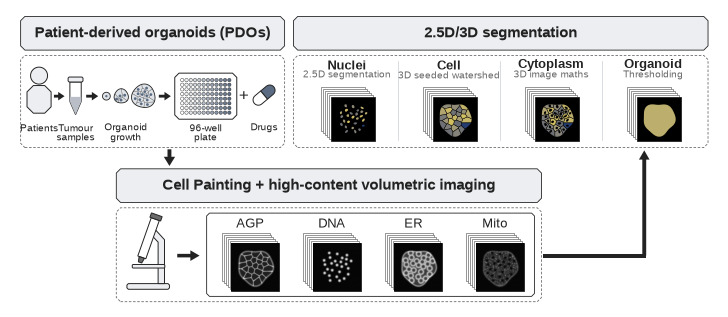

In [12]:
fig = build_figure()
plt.show()

## Export
Vector PDF and SVG keep text editable (Illustrator / Inkscape); the PNG is 600 dpi.

In [13]:
fig.savefig(output_figure_file_path, facecolor="white", dpi=600)